<a href="https://colab.research.google.com/github/Janeth172/EDP1/blob/main/PRUEBA_TEST1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ======================================
# 1. DATOS DEL EXAMEN
# ======================================

# CAMBIAR: acciones
tickers = ["GME", "NVDA", "KO"]

# CAMBIAR: fechas
hoy = "2023-12-09"
inicio_5y = "2018-12-09"
inicio_2y = "2021-12-09"

# ======================================
# 2. DESCARGAR PRECIOS
# ======================================

precios = yf.download(
    tickers,
    start=inicio_5y,
    end=hoy,
    auto_adjust=True
)["Close"]

# Ordenar correctamente las acciones
precios = precios[tickers]

# ======================================
# 3. COMPROBAR DATOS
# ======================================

print("Primeros precios:")
print(precios.head())

print("\nÚltimos precios:")
print(precios.tail())

print("\nColumnas:")
print(precios.columns)

print("\nDatos faltantes:")
print(precios.isna().sum())

# ======================================
# 4. GUARDAR EN EXCEL
# ======================================

precios.to_excel("PRECIOS_EXAMEN.xlsx")

print("\nArchivo guardado correctamente")


precios_2y = precios.loc[inicio_2y:]
print(precios_2y.head())
print(precios_2y.tail())
precios_2y.to_excel("PRECIOS_2_ANIOS.xlsx")

[*********************100%***********************]  3 of 3 completed


Primeros precios:
Ticker           GME      NVDA         KO
Date                                     
2018-12-10  3.198964  3.756124  38.947224
2018-12-11  3.131261  3.665350  39.184528
2018-12-12  3.198964  3.682911  38.931416
2018-12-13  3.092573  3.682664  39.129154
2018-12-14  3.085320  3.622312  39.026337

Últimos precios:
Ticker            GME       NVDA         KO
Date                                       
2023-12-04  16.980000  45.374485  54.153587
2023-12-05  14.910000  46.431423  54.236805
2023-12-06  14.840000  45.371490  54.181324
2023-12-07  16.360001  46.461334  54.310776
2023-12-08  15.550000  47.368706  54.190571

Columnas:
Index(['GME', 'NVDA', 'KO'], dtype='object', name='Ticker')

Datos faltantes:
Ticker
GME     0
NVDA    0
KO      0
dtype: int64

Archivo guardado correctamente
Ticker            GME       NVDA         KO
Date                                       
2021-12-09  38.939999  30.360008  47.759022
2021-12-10  39.752499  30.069254  48.995220
2021-12-13  34.

In [11]:
# Calcular rendimientos logarítmicos
rendimientos = np.log(precios / precios.shift(1))

# Eliminar la primera fila sin rendimiento
rendimientos = rendimientos.dropna()

# Seleccionar los últimos dos años
rend_2y = rendimientos.loc[inicio_2y:]

# Mostrar resultados
print(rend_2y.head())

rend_2y.to_excel("RENDIMIENTOS_2_ANIOS.xlsx")

Ticker           GME      NVDA        KO
Date                                    
2021-12-09 -0.108725 -0.042885 -0.002549
2021-12-10  0.020651 -0.009623  0.025555
2021-12-13 -0.149862 -0.069838  0.025957
2021-12-14  0.076011  0.006230  0.000692
2021-12-15  0.006075  0.072213  0.004488


Media: -0.01004669342829277
Varianza: 0.0038744221154231088
Volatilidad: 0.06224485613625522
Volatilidad porcentual: 6.2244856136255216 %
0.06224485613625522
Ticker           GME      NVDA        KO
Date                                    
2023-12-04  0.066875  0.018277  0.004859
2023-12-05  0.073519  0.017471  0.004525
2023-12-06  0.073263  0.017919  0.004543
2023-12-07  0.076035  0.018652  0.004524
2023-12-08  0.076771  0.018899  0.004549


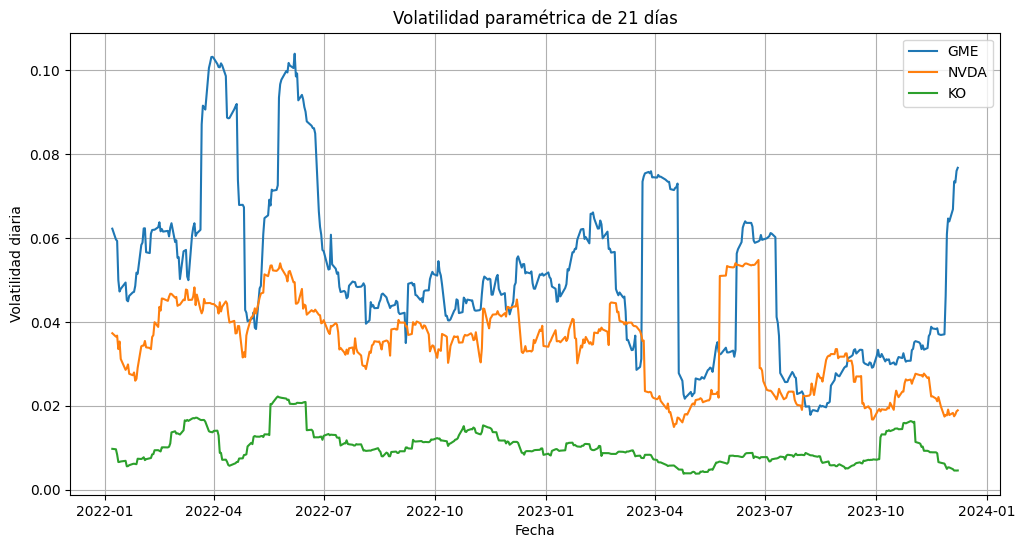

In [12]:
# Seleccionar los primeros 21 rendimientos
ventana_gme = rend_2y["GME"].iloc[0:21]

# Calcular la media
media_gme = ventana_gme.mean()

# Restar la media a cada rendimiento
diferencias = ventana_gme - media_gme

# Elevar al cuadrado
cuadrados = diferencias**2

# Sumar los cuadrados
suma_cuadrados = cuadrados.sum()

# Calcular la varianza muestral
varianza_gme = suma_cuadrados / (21 - 1)

# Calcular la volatilidad
vol_gme = np.sqrt(varianza_gme)

print("Media:", media_gme)
print("Varianza:", varianza_gme)
print("Volatilidad:", vol_gme)
print("Volatilidad porcentual:", vol_gme * 100, "%")
print(ventana_gme.std())

# Ventana de 21 días
ventana = 21

# Volatilidad paramétrica móvil
vol_param = rend_2y.rolling(window=ventana).std()

# Mostrar las últimas observaciones
print(vol_param.tail())

plt.figure(figsize=(12, 6))

plt.plot(vol_param.index, vol_param["GME"], label="GME")
plt.plot(vol_param.index, vol_param["NVDA"], label="NVDA")
plt.plot(vol_param.index, vol_param["KO"], label="KO")

plt.title("Volatilidad paramétrica de 21 días")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad diaria")

plt.legend()
plt.grid()
plt.show()

# **Volatilidad mediante simulación Monte Carlo**

Monte Carlo para todas las fechas y las tres acciones

In [13]:
def calcular_vol_mc(rendimientos, ventana, n_sims):

    # Crear una lista vacía
    volatilidades = []

    # Recorrer todos los días
    for i in range(len(rendimientos)):

        # Si todavía no tenemos 21 datos
        if i < ventana - 1:
            volatilidades.append(np.nan)

        else:
            # Seleccionar los últimos 21 rendimientos
            datos = rendimientos.iloc[i-ventana+1:i+1]

            # Calcular media y desviación estándar
            mu = datos.mean()
            sigma = datos.std()

            # Generar 1000 rendimientos simulados
            sims = np.random.normal(mu, sigma, n_sims)

            # Calcular volatilidad de las simulaciones
            vol = sims.std(ddof=1)

            # Guardar resultado
            volatilidades.append(vol)

    # Convertir la lista en una serie con fechas
    resultado = pd.Series(
        volatilidades,
        index=rendimientos.index
    )

    return resultado

In [18]:
# Aplicar la función a GME, NVDA y KO
np.random.seed(42)
vol_mc = pd.DataFrame(index=rend_2y.index)

vol_mc["GME"] = calcular_vol_mc(
    rend_2y["GME"], 21, 1000
)

vol_mc["NVDA"] = calcular_vol_mc(
    rend_2y["NVDA"], 21, 1000
)

vol_mc["KO"] = calcular_vol_mc(
    rend_2y["KO"], 21, 1000
)

print(vol_mc.tail())

                 GME      NVDA        KO
Date                                    
2023-12-04  0.064731  0.018011  0.004921
2023-12-05  0.074705  0.017806  0.004554
2023-12-06  0.072344  0.018243  0.004677
2023-12-07  0.076773  0.018932  0.004502
2023-12-08  0.075548  0.019020  0.004572


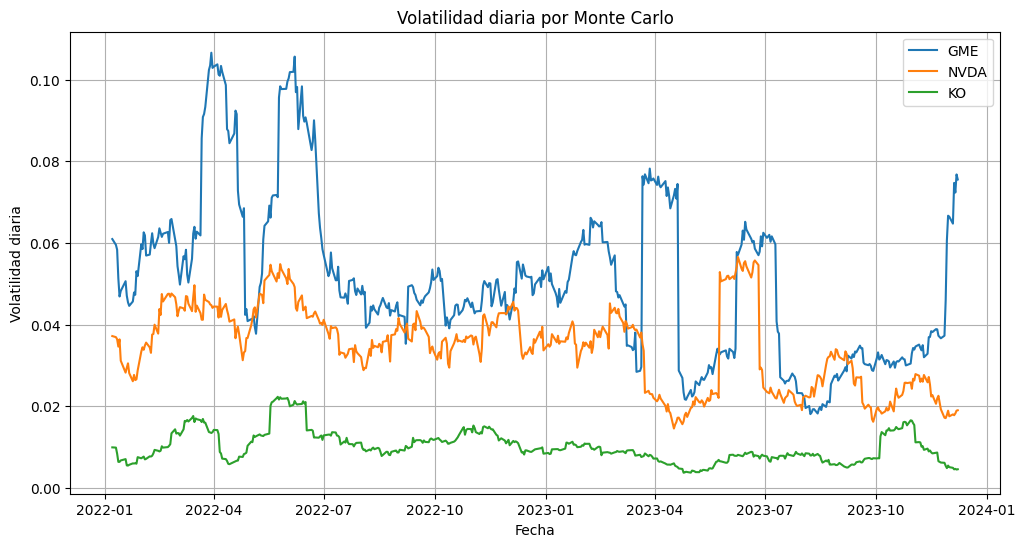

In [19]:
# Graficar las volatilidades Monte Carlo
plt.figure(figsize=(12, 6))

plt.plot(vol_mc.index, vol_mc["GME"], label="GME")
plt.plot(vol_mc.index, vol_mc["NVDA"], label="NVDA")
plt.plot(vol_mc.index, vol_mc["KO"], label="KO")

plt.title("Volatilidad diaria por Monte Carlo")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad diaria")

plt.legend()
plt.grid()
plt.show()

In [17]:
tabla_mc = pd.DataFrame({
    "Escenario": range(1, 1001),
    "Rendimiento_simulado": simulaciones
})

tabla_mc.to_excel(
    "MONTECARLO_GME.xlsx",
    index=False
)
# comprobar
print(simulaciones.std(ddof=1))

NameError: name 'simulaciones' is not defined

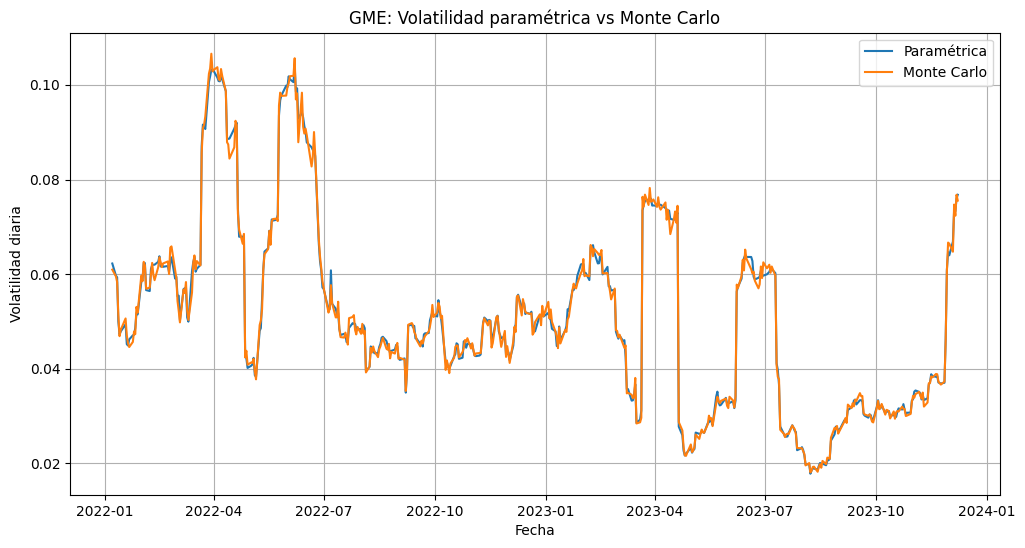

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    vol_param.index,
    vol_param["GME"],
    label="Paramétrica"
)

plt.plot(
    vol_mc.index,
    vol_mc["GME"],
    label="Monte Carlo"
)

plt.title("GME: Volatilidad paramétrica vs Monte Carlo")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad diaria")

plt.legend()
plt.grid()
plt.show()

# **VOLATILIDAD EWMA**




In [21]:

# ==========================================
# PUNTO 3 - VOLATILIDAD EWMA
# ==========================================

lam = 0.94
ventana = 21

# Crear tabla con las fechas
vol_ewma = pd.DataFrame(index=rend_2y.index)

# Repetir para cada acción
for accion in ["GME", "NVDA", "KO"]:

    # Seleccionar rendimientos
    rend = rend_2y[accion]

    # Lista de resultados
    resultados = []

    # Primeras 20 posiciones
    for i in range(ventana - 1):
        resultados.append(np.nan)

    # Varianza inicial
    varianza = rend.iloc[0:ventana].var()

    # Primera volatilidad
    resultados.append(np.sqrt(varianza))

    # Actualización diaria
    for i in range(ventana, len(rend)):

        rendimiento = rend.iloc[i]

        varianza = (
            lam * varianza
            + (1 - lam) * rendimiento**2
        )

        volatilidad = np.sqrt(varianza)

        resultados.append(volatilidad)

    # Guardar columna de la acción
    vol_ewma[accion] = resultados

# Mostrar resultados
print(vol_ewma.dropna().head())
print("-------------------------------")
print(vol_ewma.tail())

                 GME      NVDA        KO
Date                                    
2022-01-07  0.062245  0.037298  0.009711
2022-01-10  0.062718  0.036188  0.009424
2022-01-11  0.060829  0.035280  0.009138
2022-01-12  0.059128  0.034242  0.008867
2022-01-13  0.058356  0.035576  0.008718
-------------------------------
                 GME      NVDA        KO
Date                                    
2023-12-04  0.068629  0.020336  0.007877
2023-12-05  0.073766  0.020507  0.007647
2023-12-06  0.071528  0.020671  0.007418
2023-12-07  0.073347  0.020868  0.007216
2023-12-08  0.072192  0.020779  0.007017


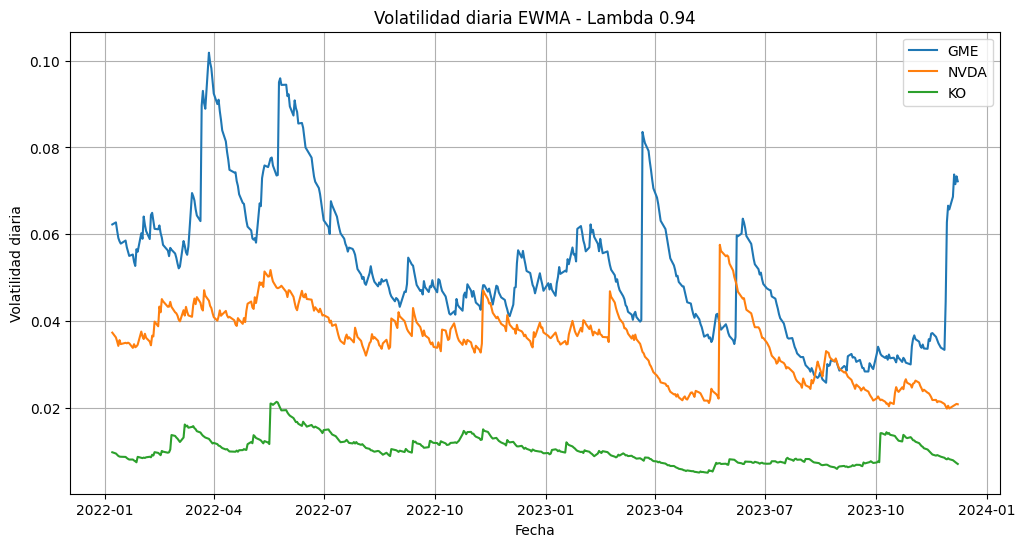

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(
    vol_ewma.index,
    vol_ewma["GME"],
    label="GME"
)

plt.plot(
    vol_ewma.index,
    vol_ewma["NVDA"],
    label="NVDA"
)

plt.plot(
    vol_ewma.index,
    vol_ewma["KO"],
    label="KO"
)

plt.title("Volatilidad diaria EWMA - Lambda 0.94")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad diaria")

plt.legend()
plt.grid()
plt.show()

# **COMPARAR TRES VOLATILIDADES**

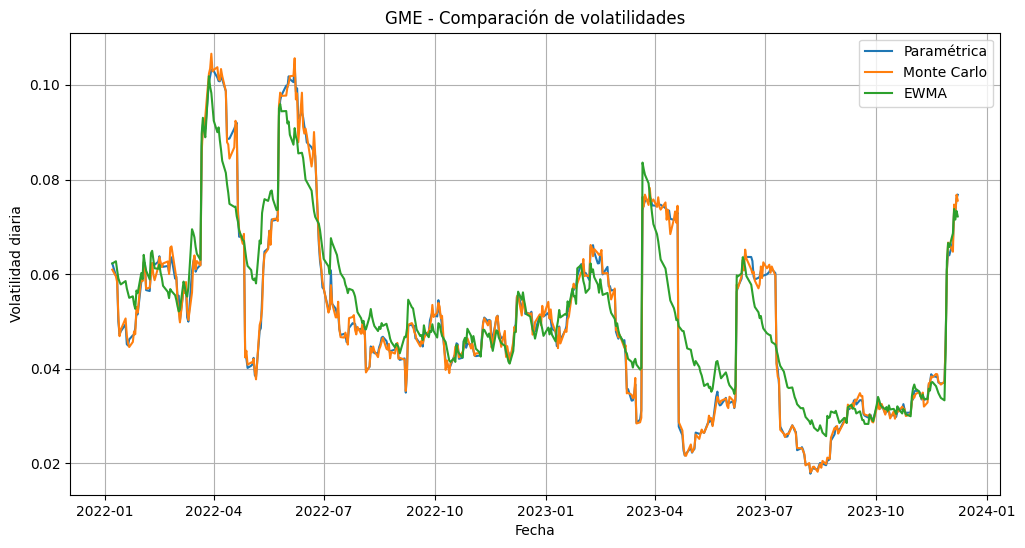

In [23]:
plt.figure(figsize=(12, 6))

plt.plot(
    vol_param.index,
    vol_param["GME"],
    label="Paramétrica"
)

plt.plot(
    vol_mc.index,
    vol_mc["GME"],
    label="Monte Carlo"
)

plt.plot(
    vol_ewma.index,
    vol_ewma["GME"],
    label="EWMA"
)

plt.title("GME - Comparación de volatilidades")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad diaria")

plt.legend()
plt.grid()
plt.show()

# **PORTAFOLIO**

In [24]:
# orden de volatilidades
print(vol_param.iloc[-1].sort_values(ascending=False))

Ticker
GME     0.076771
NVDA    0.018899
KO      0.004549
Name: 2023-12-08 00:00:00, dtype: float64


In [25]:

# ==========================================
# PUNTO 4 - CONSTRUCCION DEL PORTAFOLIO
# ==========================================

# 1. Pesos de inversion
w_gme = 0.20
w_nvda = 0.30
w_ko = 0.50

# 2. Comprobar suma de pesos
suma_pesos = w_gme + w_nvda + w_ko
print("Suma de pesos:", suma_pesos)

# 3. Convertir rendimientos logaritmicos
#    a rendimientos simples
rend_simples = np.exp(rend_2y) - 1

# 4. Calcular rendimiento diario del portafolio
rend_port = (
    w_gme * rend_simples["GME"]
    + w_nvda * rend_simples["NVDA"]
    + w_ko * rend_simples["KO"]
)

# 5. Calcular rendimiento promedio
media_port = rend_port.mean()

# 6. Calcular varianza muestral
var_port = rend_port.var()

# 7. Calcular volatilidad diaria
vol_port = np.sqrt(var_port)

# 8. Mostrar resultados
print("Rendimiento promedio:", media_port)
print("Varianza:", var_port)
print("Volatilidad diaria:", vol_port)
print("Volatilidad porcentual:", vol_port * 100, "%")

Suma de pesos: 1.0
Rendimiento promedio: 0.00048446265258753844
Varianza: 0.0003981390495911742
Volatilidad diaria: 0.019953422002031988
Volatilidad porcentual: 1.9953422002031989 %


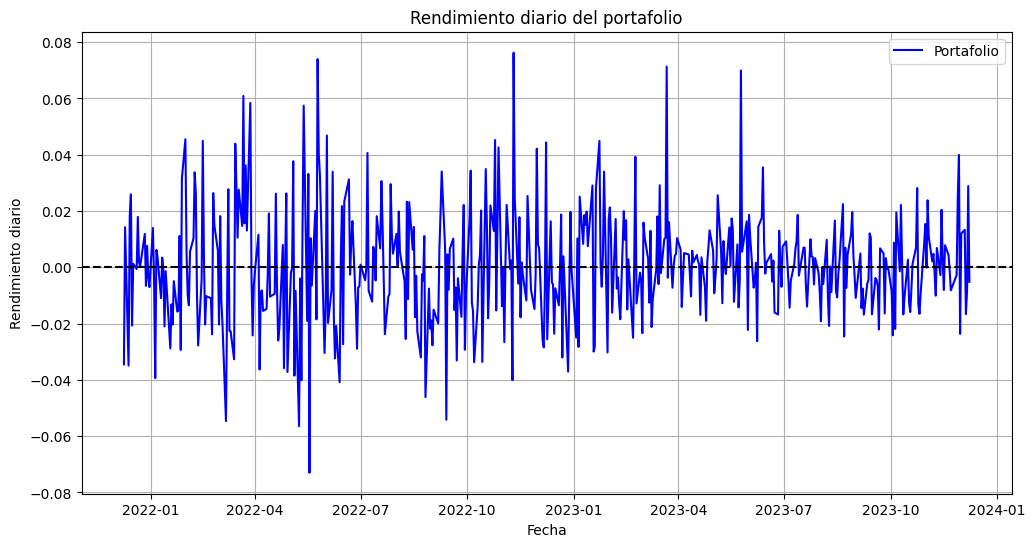

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    rend_port.index,
    rend_port,
    label="Portafolio",
    color="blue"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Rendimiento diario del portafolio")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento diario")

plt.legend()
plt.grid()
plt.show()

**Distribución de $1,000,000 entre GME, NVDA y KO**

Inversión individual=Capital inicial $\times$ Peso


In [27]:

# ==========================================
# PUNTO 5 - DISTRIBUCION DEL CAPITAL
# ==========================================

# 1. Capital disponible
capital_inicial = 1_000_000

# 2. Pesos del portafolio
w_gme = 0.20
w_nvda = 0.30
w_ko = 0.50

# 3. Calcular inversion por accion
inversion_gme = capital_inicial * w_gme
inversion_nvda = capital_inicial * w_nvda
inversion_ko = capital_inicial * w_ko

# 4. Calcular inversion total
inversion_total = (
    inversion_gme
    + inversion_nvda
    + inversion_ko
)

# 5. Comprobar los pesos
suma_pesos = w_gme + w_nvda + w_ko

# 6. Mostrar resultados
print("GME:", inversion_gme)
print("NVDA:", inversion_nvda)
print("KO:", inversion_ko)

print("Total invertido:", inversion_total)
print("Suma de pesos:", suma_pesos)


GME: 200000.0
NVDA: 300000.0
KO: 500000.0
Total invertido: 1000000.0
Suma de pesos: 1.0


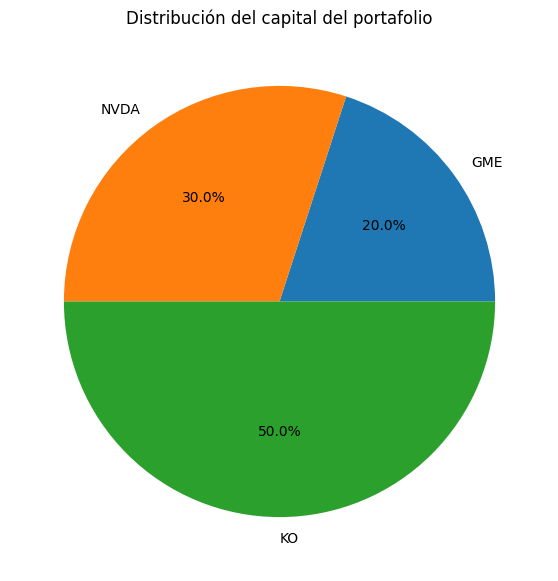

In [28]:
# Gráfica de distribución del capital
acciones = ["GME", "NVDA", "KO"]

inversiones = [
    inversion_gme,
    inversion_nvda,
    inversion_ko
]

plt.figure(figsize=(7, 7))

plt.pie(
    inversiones,
    labels=acciones,
    autopct="%1.1f%%"
)

plt.title("Distribución del capital del portafolio")

plt.show()

**Valor en Riesgo (VaR) diario al 95% de GME, NVDA y KO**

VAR PORCENTUAL: $VaR_{\%}=Z\sigma$ = $1.65\sigma$

VaR monetario: $VaR_{\$}=V_0\times VaR_{\%}$ = $V_0\times 1.65\sigma$

In [29]:

# ==========================================
# PUNTO 6 - VaR INDIVIDUAL AL 95%
# ==========================================

# 1. Valor critico
Z = 1.65

# 2. VaR porcentual
var_gme_pct = Z * vol_param["GME"]
var_nvda_pct = Z * vol_param["NVDA"]
var_ko_pct = Z * vol_param["KO"]

# 3. VaR monetario
var_gme_mxn = inversion_gme * var_gme_pct
var_nvda_mxn = inversion_nvda * var_nvda_pct
var_ko_mxn = inversion_ko * var_ko_pct

# 4. Tabla de VaR porcentual
var_pct = pd.DataFrame({
    "GME": var_gme_pct,
    "NVDA": var_nvda_pct,
    "KO": var_ko_pct
})

# 5. Tabla de VaR monetario
var_mxn = pd.DataFrame({
    "GME": var_gme_mxn,
    "NVDA": var_nvda_mxn,
    "KO": var_ko_mxn
})

# 6. Mostrar resultados
print("VaR porcentual:")
print(var_pct.tail() * 100)

print("\nVaR monetario:")
print(var_mxn.tail())


VaR porcentual:
                  GME      NVDA        KO
Date                                     
2023-12-04  11.034302  3.015752  0.801804
2023-12-05  12.130648  2.882743  0.746587
2023-12-06  12.088404  2.956704  0.749637
2023-12-07  12.545699  3.077559  0.746478
2023-12-08  12.667268  3.118305  0.750601

VaR monetario:
                     GME         NVDA           KO
Date                                              
2023-12-04  22068.603605  9047.257307  4009.021295
2023-12-05  24261.295162  8648.228201  3732.934516
2023-12-06  24176.807743  8870.111043  3748.186389
2023-12-07  25091.397337  9232.676132  3732.390908
2023-12-08  25334.536670  9354.914448  3753.007207


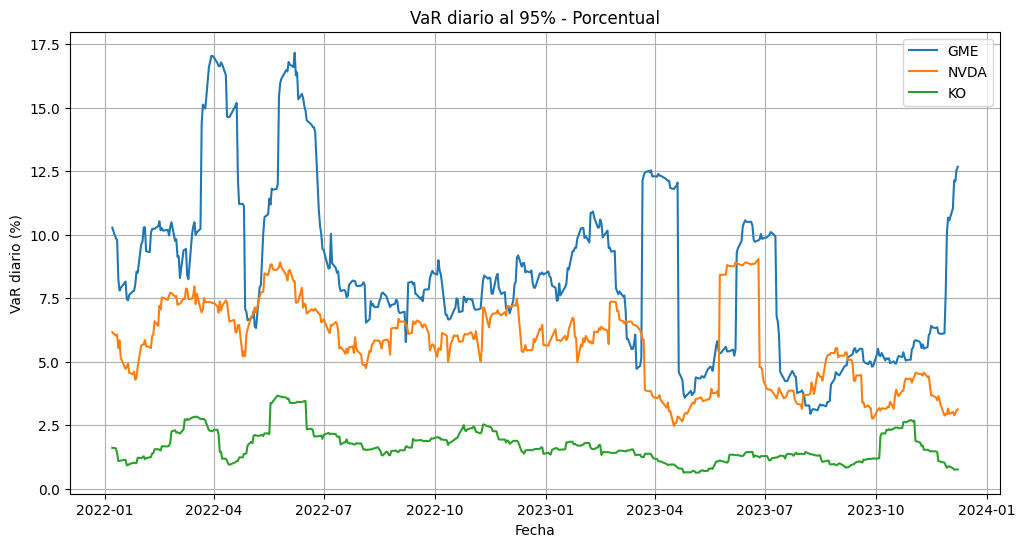

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(var_pct.index, var_pct["GME"] * 100, label="GME")
plt.plot(var_pct.index, var_pct["NVDA"] * 100, label="NVDA")
plt.plot(var_pct.index, var_pct["KO"] * 100, label="KO")

plt.title("VaR diario al 95% - Porcentual")
plt.xlabel("Fecha")
plt.ylabel("VaR diario (%)")

plt.legend()
plt.grid()
plt.show()

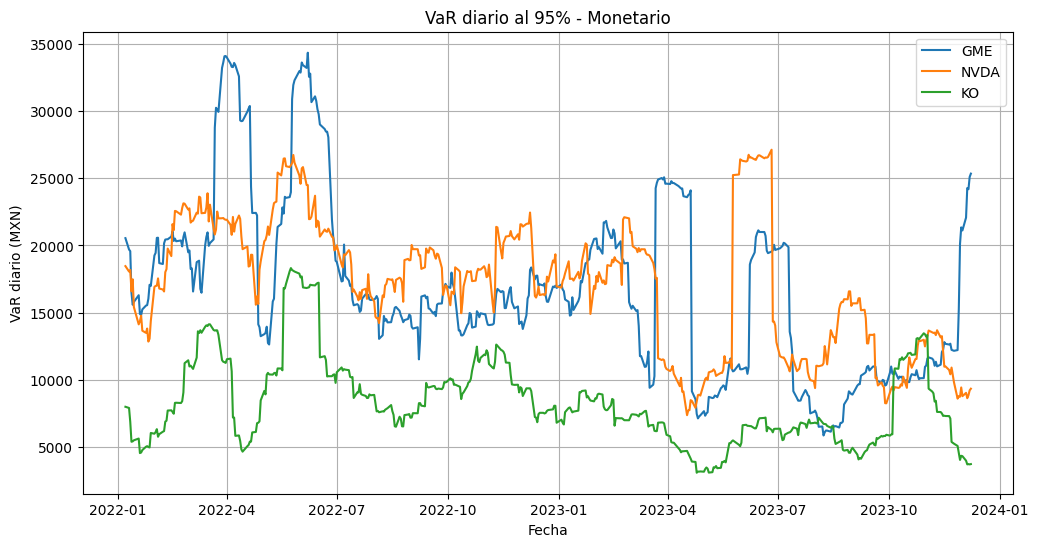

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(var_mxn.index, var_mxn["GME"], label="GME")
plt.plot(var_mxn.index, var_mxn["NVDA"], label="NVDA")
plt.plot(var_mxn.index, var_mxn["KO"], label="KO")

plt.title("VaR diario al 95% - Monetario")
plt.xlabel("Fecha")
plt.ylabel("VaR diario (MXN)")

plt.legend()
plt.grid()
plt.show()

**Valor en Riesgo (VaR) diario al 95% del portafolio completo**

VaR Porcentual:  $VaR_{p,\%} = 1.65\sigma_p$

VaR Monetario: $VaR_{p,\$}=V_0(1.65\sigma_p)$


In [33]:

# ==========================================
# PUNTO 7 - VaR DEL PORTAFOLIO AL 95%
# ==========================================

# 1. Parametros
Z = 1.65
capital_inicial = 1_000_000
ventana = 21

# 2. Volatilidad movil del portafolio
vol_port_21 = rend_port.rolling(ventana).std()

# 3. VaR porcentual
var_port_pct = Z * vol_port_21

# 4. VaR monetario
var_port_mxn = capital_inicial * var_port_pct

# 5. Crear tabla de resultados
tabla_var_port = pd.DataFrame({
    "Rendimiento": rend_port,
    "Volatilidad_21": vol_port_21,
    "VaR_porcentual": var_port_pct,
    "VaR_monetario": var_port_mxn
})

# 6. Mostrar ultimos resultados
print(tabla_var_port.tail())

# 7. Mostrar resultado final
print("\nUltimo VaR del portafolio")

print("Volatilidad:", vol_port_21.iloc[-1])

print("VaR porcentual:", var_port_pct.iloc[-1] * 100, "%")

print("VaR monetario:", var_port_mxn.iloc[-1])


            Rendimiento  Volatilidad_21  VaR_porcentual  VaR_monetario
Date                                                                  
2023-12-04     0.013313        0.013666        0.022548   22548.497494
2023-12-05    -0.016625        0.014288        0.023575   23574.510569
2023-12-06    -0.008299        0.014489        0.023908   23907.575858
2023-12-07     0.028886        0.015612        0.025760   25759.875687
2023-12-08    -0.005150        0.015681        0.025874   25873.561507

Ultimo VaR del portafolio
Volatilidad: 0.015680946367865572
VaR porcentual: 2.5873561506978193 %
VaR monetario: 25873.561506978192


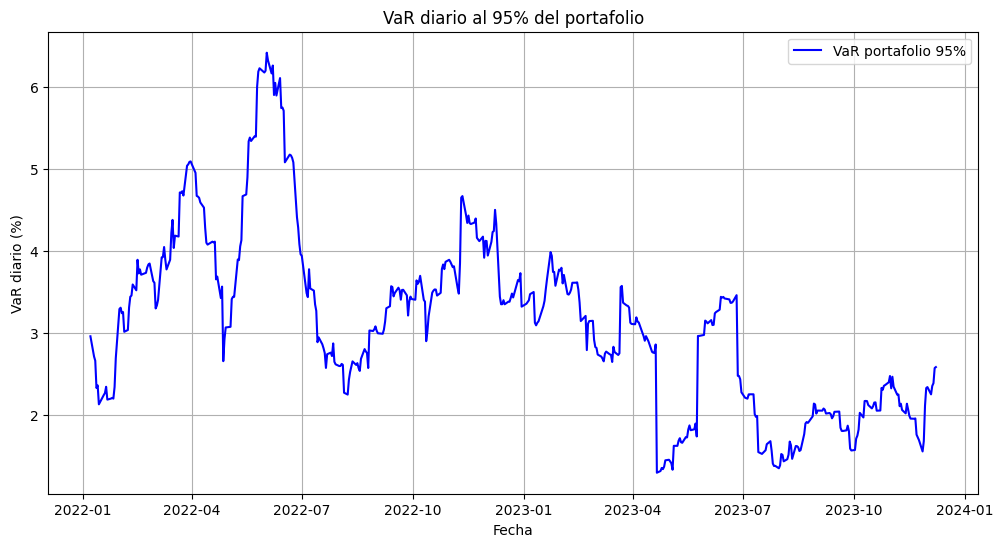

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(
    var_port_pct.index,
    var_port_pct * 100,
    label="VaR portafolio 95%",
    color="blue"
)

plt.title("VaR diario al 95% del portafolio")
plt.xlabel("Fecha")
plt.ylabel("VaR diario (%)")

plt.legend()
plt.grid()
plt.show()

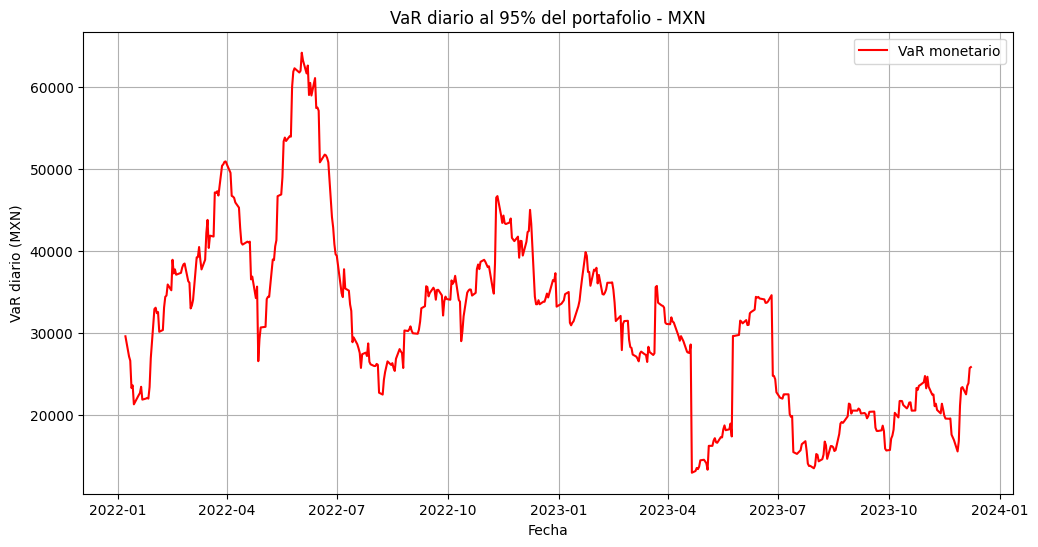

In [35]:
plt.figure(figsize=(12, 6))

plt.plot(
    var_port_mxn.index,
    var_port_mxn,
    label="VaR monetario",
    color="red"
)

plt.title("VaR diario al 95% del portafolio - MXN")
plt.xlabel("Fecha")
plt.ylabel("VaR diario (MXN)")

plt.legend()
plt.grid()
plt.show()

**Cálculo de las Betas individuales y la Beta del portafolio**

In [36]:

# ==========================================
# PUNTO 8 - BETAS INDIVIDUALES
# ==========================================

# 1. Descargar el mercado
sp500 = yf.download(
    "^GSPC",
    start=inicio_5y,
    end=hoy,
    auto_adjust=True
)["Close"]

# 2. Seleccionar la serie del S&P 500
if isinstance(sp500, pd.DataFrame):
    sp500 = sp500["^GSPC"]

# 3. Rendimientos logaritmicos
rend_sp500 = np.log(sp500 / sp500.shift(1))
rend_sp500 = rend_sp500.dropna()
rend_sp500 = rend_sp500.loc[inicio_2y:]

# 4. Alinear las fechas
datos_beta = rend_2y.copy()
datos_beta["SP500"] = rend_sp500
datos_beta = datos_beta.dropna()

# 5. Seleccionar rendimientos
rend_mercado = datos_beta["SP500"]

rend_gme = datos_beta["GME"]
rend_nvda = datos_beta["NVDA"]
rend_ko = datos_beta["KO"]

# 6. Varianza del mercado
var_mercado = rend_mercado.var()

# 7. Covarianzas
cov_gme = rend_gme.cov(rend_mercado)
cov_nvda = rend_nvda.cov(rend_mercado)
cov_ko = rend_ko.cov(rend_mercado)

# 8. Betas individuales
beta_gme = cov_gme / var_mercado
beta_nvda = cov_nvda / var_mercado
beta_ko = cov_ko / var_mercado

# 9. Mostrar resultados
print("Beta GME:", beta_gme)
print("Beta NVDA:", beta_nvda)
print("Beta KO:", beta_ko)

# 10. Exportar datos para Excel
datos_beta.to_excel("DATOS_BETAS.xlsx")

[*********************100%***********************]  1 of 1 completed

Beta GME: 1.8385922593217519
Beta NVDA: 2.1992541773031453
Beta KO: 0.4549736851170332


In [37]:

# ==========================================
# PUNTO 9 - BETA DEL PORTAFOLIO
# ==========================================

# 1. Pesos
w_gme = 0.20
w_nvda = 0.30
w_ko = 0.50

# 2. Comprobar pesos
suma_pesos = w_gme + w_nvda + w_ko

# 3. Beta del portafolio
beta_port = (
    w_gme * beta_gme
    + w_nvda * beta_nvda
    + w_ko * beta_ko
)

# 4. Mostrar resultados
print("Suma de pesos:", suma_pesos)

print("Beta GME:", beta_gme)
print("Beta NVDA:", beta_nvda)
print("Beta KO:", beta_ko)

print("Beta del portafolio:", beta_port)


Suma de pesos: 1.0
Beta GME: 1.8385922593217519
Beta NVDA: 2.1992541773031453
Beta KO: 0.4549736851170332
Beta del portafolio: 1.2549815476138106


**SMA, WMA y EMA para GME, NVDA y KO**

Ultimas EMA de GME:
Date
2023-12-04    13.908763
2023-12-05    13.999784
2023-12-06    14.076167
2023-12-07    14.283789
2023-12-08    14.398899
dtype: float64

Ultimas WMA de NVDA:
Date
2023-12-04    47.839454
2023-12-05    47.724503
2023-12-06    47.506440
2023-12-07    47.388506
2023-12-08    47.350276
dtype: float64

Ultimas SMA de KO:
Date
2023-12-04    52.929874
2023-12-05    53.034143
2023-12-06    53.125723
2023-12-07    53.214296
2023-12-08    53.301075
Name: KO, dtype: float64


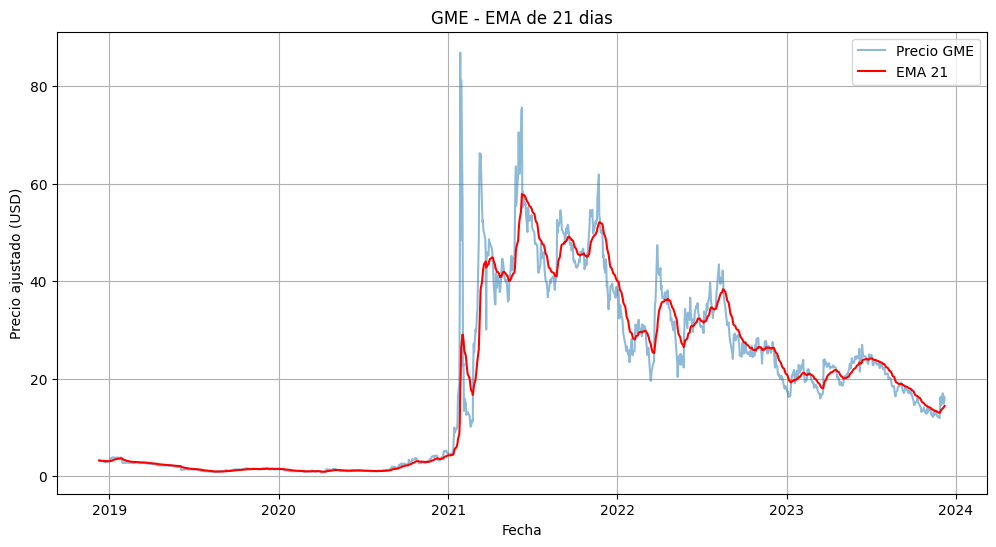

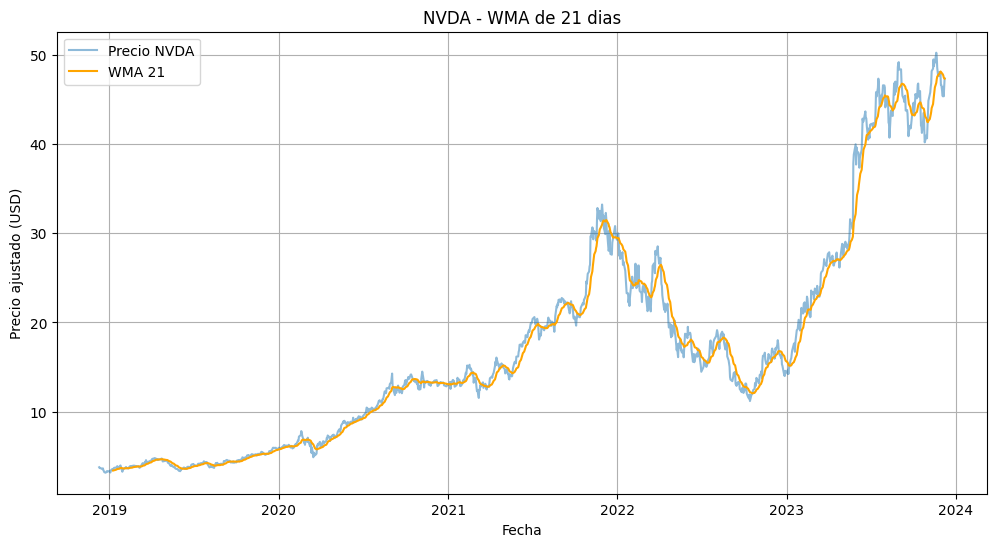

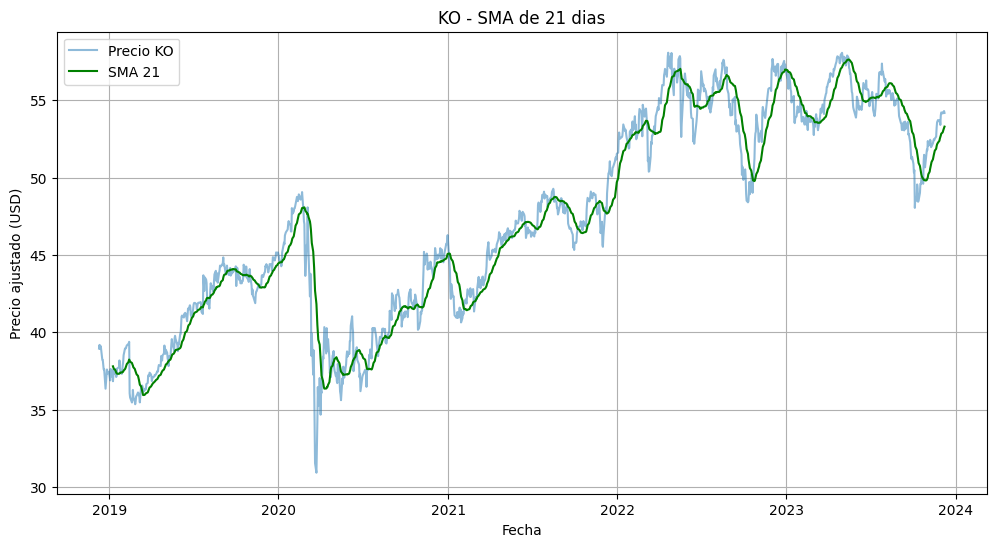

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

# ==========================================
# PUNTO 10 - MEDIAS MOVILES
# SMA, WMA Y EMA
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. SELECCIONAR PRECIOS
# ==========================================
# Usamos los precios descargados anteriormente
precio_gme = precios["GME"]
precio_nvda = precios["NVDA"]
precio_ko = precios["KO"]

# Ventana de 21 dias
ventana = 21

# ==========================================
# 2. SMA - COCA-COLA
# ==========================================
# Promedio movil de 21 precios
sma_ko = precio_ko.rolling(ventana).mean()


# ==========================================
# 3. WMA - NVIDIA
# ==========================================
# Crear pesos del 1 al 21
pesos_wma = np.arange(1, ventana + 1)

# Lista vacia para guardar resultados
resultados_wma = []

# Recorrer todos los precios de NVIDIA
for i in range(len(precio_nvda)):

    # Si no tenemos 21 precios
    if i < ventana - 1:
        resultados_wma.append(np.nan)

    else:
        # Seleccionar los ultimos 21 precios
        datos = precio_nvda.iloc[i-ventana+1:i+1]

        # Calcular suma ponderada
        suma_ponderada = 0

        for j in range(ventana):
            suma_ponderada = (
                suma_ponderada
                + datos.iloc[j] * pesos_wma[j]
            )

        # Calcular WMA
        wma = suma_ponderada / pesos_wma.sum()

        # Guardar resultado
        resultados_wma.append(wma)

# Convertir resultados en serie con fechas
wma_nvda = pd.Series(
    resultados_wma,
    index=precio_nvda.index
)


# ==========================================
# 4. EMA - GAMESTOP
# ==========================================

# Calcular factor de suavizamiento
alpha = 2 / (ventana + 1)

# Primera EMA = primer precio
ema_anterior = precio_gme.iloc[0]

# Lista de resultados
resultados_ema = [ema_anterior]

# Recorrer desde el segundo precio
for i in range(1, len(precio_gme)):

    # Precio actual
    precio_actual = precio_gme.iloc[i]

    # Formula EMA
    ema_actual = (
        alpha * precio_actual
        + (1 - alpha) * ema_anterior
    )

    # Guardar EMA
    resultados_ema.append(ema_actual)

    # Actualizar EMA anterior
    ema_anterior = ema_actual

# Convertir resultados en serie
ema_gme = pd.Series(
    resultados_ema,
    index=precio_gme.index
)


# ==========================================
# 5. MOSTRAR RESULTADOS
# ==========================================

print("Ultimas EMA de GME:")
print(ema_gme.tail())

print("\nUltimas WMA de NVDA:")
print(wma_nvda.tail())

print("\nUltimas SMA de KO:")
print(sma_ko.tail())


# ==========================================
# 6. GRAFICA GME - EMA
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(precio_gme.index, precio_gme,
         label="Precio GME", alpha=0.5)

plt.plot(ema_gme.index, ema_gme,
         label="EMA 21", color="red")

plt.title("GME - EMA de 21 dias")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado (USD)")
plt.legend()
plt.grid()
plt.show()


# ==========================================
# 7. GRAFICA NVDA - WMA
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(precio_nvda.index, precio_nvda,
         label="Precio NVDA", alpha=0.5)

plt.plot(wma_nvda.index, wma_nvda,
         label="WMA 21", color="orange")

plt.title("NVDA - WMA de 21 dias")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado (USD)")
plt.legend()
plt.grid()
plt.show()


# ==========================================
# 8. GRAFICA KO - SMA
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(precio_ko.index, precio_ko,
         label="Precio KO", alpha=0.5)

plt.plot(sma_ko.index, sma_ko,
         label="SMA 21", color="green")

plt.title("KO - SMA de 21 dias")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado (USD)")
plt.legend()
plt.grid()
plt.show()


# ==========================================
# 9. EXPORTAR RESULTADOS A EXCEL
# ==========================================

tabla_medias = precios.copy()

tabla_medias["EMA_GME"] = ema_gme
tabla_medias["WMA_NVDA"] = wma_nvda
tabla_medias["SMA_KO"] = sma_ko

tabla_medias.to_excel("PUNTO10_MEDIAS.xlsx")

# Descargar en Google Colab
from google.colab import files
files.download("PUNTO10_MEDIAS.xlsx")


**RSI**

$\Delta $$P_t$ = $P_t-P_{t-1}$      con

$G_t=\max(\Delta P_t,0)$ y $
L_t=\max(-\Delta P_t,0)$

In [40]:

# ==========================================
# PUNTO 11 - RSI DE GAMESTOP
# ==========================================

# 1. Seleccionar precios
precio_gme = precios["GME"]

# 2. Ventana del RSI
ventana_rsi = 14

# 3. Calcular P_t - P_t-1
# .diff() resta a cada precio el precio anterior.
cambios = precio_gme.diff()

# 4. Separar ganancias y perdidas
ganancias = cambios.clip(lower=0)   #
perdidas = -cambios.clip(upper=0)

# 5. Promedios moviles de 14 periodos
prom_ganancias = ganancias.rolling(ventana_rsi).mean()
prom_perdidas = perdidas.rolling(ventana_rsi).mean()

# 6. Calcular RSI
total = prom_ganancias + prom_perdidas

rsi_gme = 100 * prom_ganancias / total

# 7. Casos especiales
rsi_gme = rsi_gme.mask(
    (prom_perdidas == 0) & (prom_ganancias > 0),
    100
)

rsi_gme = rsi_gme.mask(
    (prom_ganancias == 0) & (prom_perdidas > 0),
    0
)

# Si ambas son cero, el RSI queda sin definir
# porque no hubo variaciones de precio.

# 8. Mostrar resultados
print("Ultimos valores RSI de GME:")
print(rsi_gme.tail())


Ultimos valores RSI de GME:
Date
2023-12-04    70.234110
2023-12-05    57.573475
2023-12-06    56.052428
2023-12-07    63.927277
2023-12-08    58.961595
Name: GME, dtype: float64


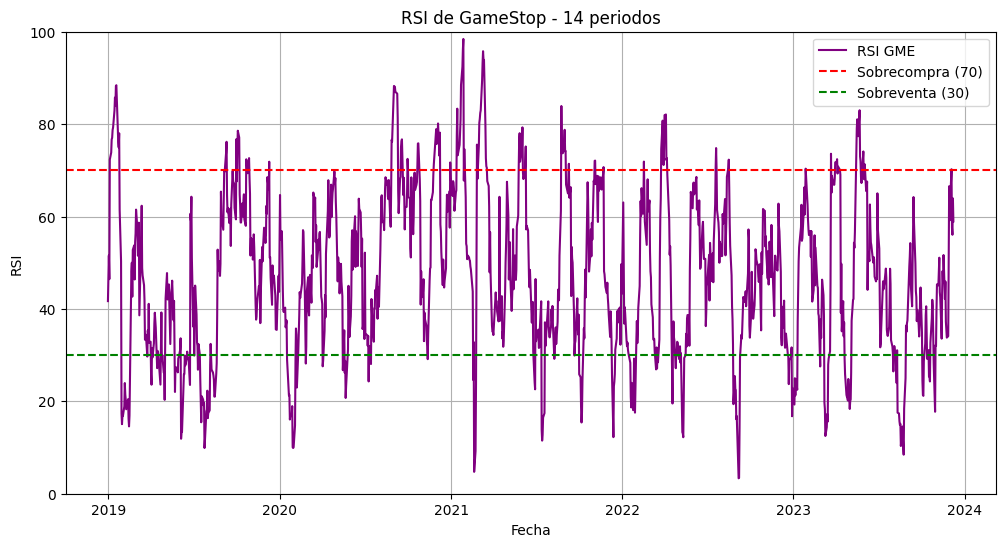

In [41]:
plt.figure(figsize=(12, 6))

plt.plot(
    rsi_gme.index,
    rsi_gme,
    label="RSI GME",
    color="purple"
)

plt.axhline(
    70,
    color="red",
    linestyle="--",
    label="Sobrecompra (70)"
)

plt.axhline(
    30,
    color="green",
    linestyle="--",
    label="Sobreventa (30)"
)

plt.title("RSI de GameStop - 14 periodos")
plt.xlabel("Fecha")
plt.ylabel("RSI")

plt.ylim(0, 100)
plt.legend()
plt.grid()
plt.show()

**MACD**


RSI GME:
Date
2023-12-04    70.234110
2023-12-05    57.573475
2023-12-06    56.052428
2023-12-07    63.927277
2023-12-08    58.961595
Name: GME, dtype: float64

MACD NVDA:
Date
2023-12-04    0.531937
2023-12-05    0.425471
2023-12-06    0.252656
2023-12-07    0.201319
2023-12-08    0.231187
dtype: float64

Senal NVDA:
Date
2023-12-04    0.996487
2023-12-05    0.882284
2023-12-06    0.756358
2023-12-07    0.645351
2023-12-08    0.562518
dtype: float64

MACD KO:
Date
2023-12-04    0.691137
2023-12-05    0.699199
2023-12-06    0.693122
2023-12-07    0.690789
2023-12-08    0.671499
dtype: float64

Senal KO:
Date
2023-12-04    0.598167
2023-12-05    0.618374
2023-12-06    0.633323
2023-12-07    0.644816
2023-12-08    0.650153
dtype: float64


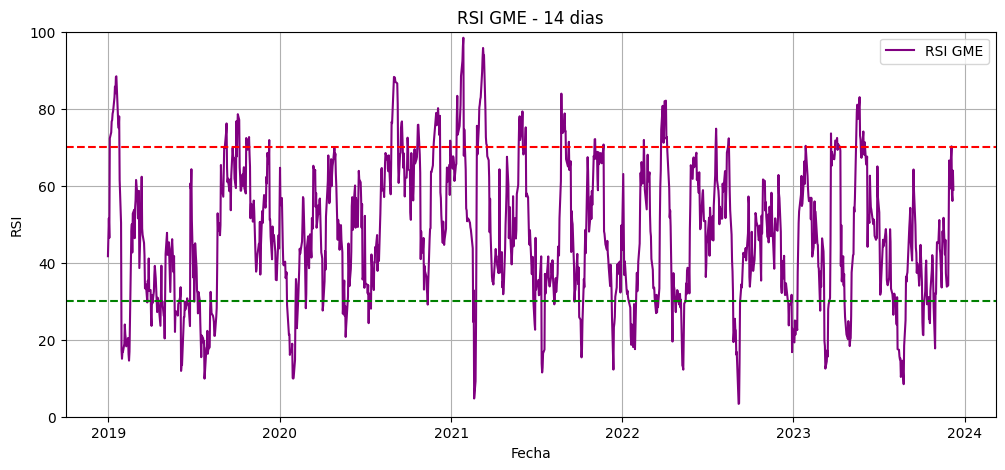

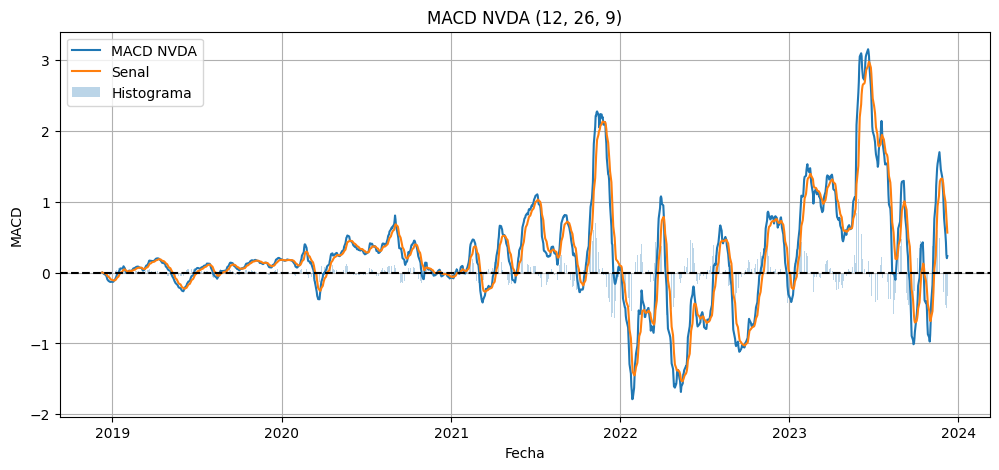

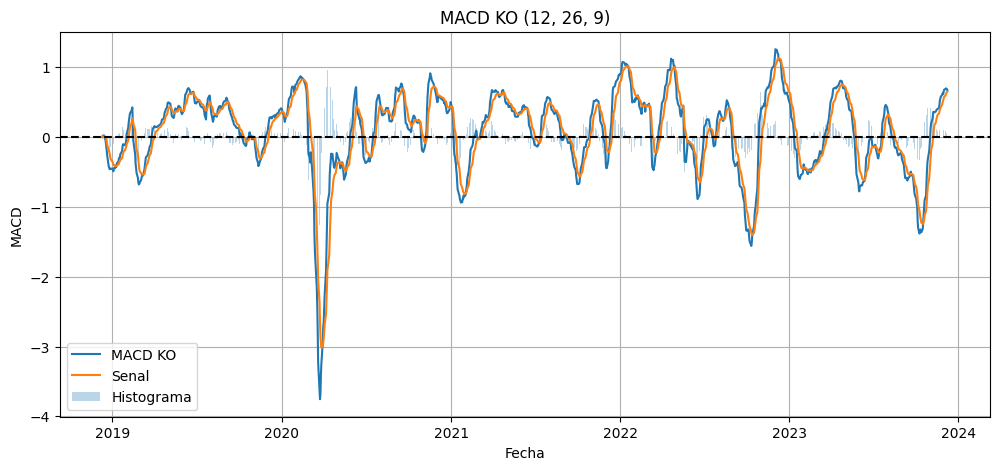

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:

# ==========================================
# PUNTO 11
# NVDA Y KO: MACD
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. PRECIOS
# ==========================================

precio_gme = precios["GME"]
precio_nvda = precios["NVDA"]
precio_ko = precios["KO"]

# ==========================================
# 3. FUNCION EMA PARA EL MACD
# ==========================================

def calcular_ema(serie, n):

    alpha = 2 / (n + 1)

    ema_anterior = serie.iloc[0]
    resultados = [ema_anterior]

    for i in range(1, len(serie)):

        valor_actual = serie.iloc[i]

        ema_actual = (
            alpha * valor_actual
            + (1 - alpha) * ema_anterior
        )

        resultados.append(ema_actual)
        ema_anterior = ema_actual

    return pd.Series(resultados, index=serie.index)


# ==========================================
# 4. MACD DE NVDA
# ==========================================

ema12_nvda = calcular_ema(precio_nvda, 12)
ema26_nvda = calcular_ema(precio_nvda, 26)

macd_nvda = ema12_nvda - ema26_nvda

senal_nvda = calcular_ema(macd_nvda, 9)

hist_nvda = macd_nvda - senal_nvda

# ==========================================
# 5. MACD DE KO
# ==========================================

ema12_ko = calcular_ema(precio_ko, 12)
ema26_ko = calcular_ema(precio_ko, 26)

macd_ko = ema12_ko - ema26_ko

senal_ko = calcular_ema(macd_ko, 9)

hist_ko = macd_ko - senal_ko

# ==========================================
# 6. MOSTRAR RESULTADOS
# ==========================================

print("RSI GME:")
print(rsi_gme.tail())

print("\nMACD NVDA:")
print(macd_nvda.tail())

print("\nSenal NVDA:")
print(senal_nvda.tail())

print("\nMACD KO:")
print(macd_ko.tail())

print("\nSenal KO:")
print(senal_ko.tail())

# ==========================================
# 7. GRAFICA RSI GME
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(rsi_gme.index, rsi_gme,
         label="RSI GME", color="purple")

plt.axhline(70, color="red", linestyle="--")
plt.axhline(30, color="green", linestyle="--")

plt.title("RSI GME - 14 dias")
plt.xlabel("Fecha")
plt.ylabel("RSI")
plt.ylim(0, 100)
plt.legend()
plt.grid()
plt.show()

# ==========================================
# 8. GRAFICA MACD NVDA
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(macd_nvda.index, macd_nvda,
         label="MACD NVDA")

plt.plot(senal_nvda.index, senal_nvda,
         label="Senal")

plt.bar(hist_nvda.index, hist_nvda,
        label="Histograma", alpha=0.3)

plt.axhline(0, color="black", linestyle="--")

plt.title("MACD NVDA (12, 26, 9)")
plt.xlabel("Fecha")
plt.ylabel("MACD")
plt.legend()
plt.grid()
plt.show()

# ==========================================
# 9. GRAFICA MACD KO
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(macd_ko.index, macd_ko,
         label="MACD KO")

plt.plot(senal_ko.index, senal_ko,
         label="Senal")

plt.bar(hist_ko.index, hist_ko,
        label="Histograma", alpha=0.3)

plt.axhline(0, color="black", linestyle="--")

plt.title("MACD KO (12, 26, 9)")
plt.xlabel("Fecha")
plt.ylabel("MACD")
plt.legend()
plt.grid()
plt.show()

# ==========================================
# 10. EXPORTAR A EXCEL
# ==========================================

tabla_indicadores = pd.DataFrame(index=precios.index)

tabla_indicadores["Precio_GME"] = precio_gme
tabla_indicadores["RSI_GME"] = rsi_gme

tabla_indicadores["Precio_NVDA"] = precio_nvda
tabla_indicadores["EMA12_NVDA"] = ema12_nvda
tabla_indicadores["EMA26_NVDA"] = ema26_nvda
tabla_indicadores["MACD_NVDA"] = macd_nvda
tabla_indicadores["Senal_NVDA"] = senal_nvda
tabla_indicadores["Hist_NVDA"] = hist_nvda

tabla_indicadores["Precio_KO"] = precio_ko
tabla_indicadores["EMA12_KO"] = ema12_ko
tabla_indicadores["EMA26_KO"] = ema26_ko
tabla_indicadores["MACD_KO"] = macd_ko
tabla_indicadores["Senal_KO"] = senal_ko
tabla_indicadores["Hist_KO"] = hist_ko

tabla_indicadores.to_excel(
    "PUNTO11_RSI_MACD.xlsx"
)

from google.colab import files
files.download("PUNTO11_RSI_MACD.xlsx")


**Proyección del S&P 500 mediante Movimiento Browniano Geométrico (GBM) y Monte Carlo**


$
S_{t+\Delta t} = S_t\exp (
\left(\mu-\frac{\sigma^2}{2}\right)\Delta t
+\sigma\sqrt{\Delta t}Z_t
$

Media logaritmica diaria: -4.1379793438863146e-05
Varianza diaria: 0.00015184443048874778
Volatilidad diaria: 0.012322517213976526
Precio inicial: 4604.3701171875

Precio promedio final: 4648.365719122848
Percentil 5 final: 2841.1580150734676
Percentil 95 final: 6951.830463603548
Rendimiento promedio 2 anios: 0.95551836224283 %


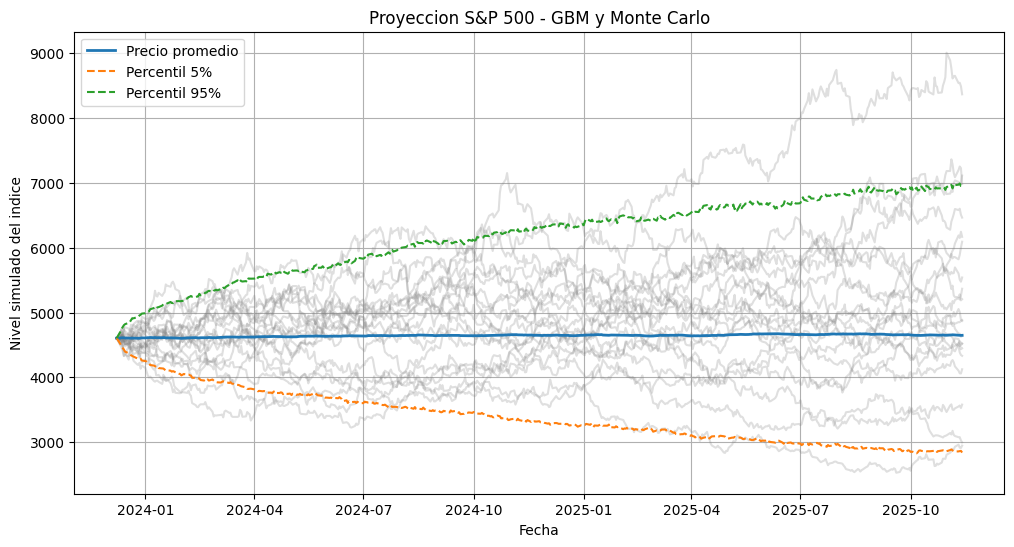

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:

# ==========================================
# PUNTO 12 - GBM + MONTE CARLO
# PROYECCION DEL S&P 500 A 2 ANIOS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETROS HISTORICOS
# ==========================================

# Rendimientos del mercado del punto 8
rend_mercado = datos_beta["SP500"]

# Media logaritmica diaria
media_diaria = rend_mercado.mean()

# Varianza diaria
varianza_diaria = rend_mercado.var()

# Desviacion estandar diaria
sigma_diaria = np.sqrt(varianza_diaria)

# Ultimo nivel conocido del S&P 500
S0 = float(sp500.loc[:hoy].iloc[-1])

# ==========================================
# 2. PARAMETROS DE SIMULACION
# ==========================================

dias = 504
n_sims = 1000

# ==========================================
# 3. GENERAR NUMEROS ALEATORIOS
# ==========================================

np.random.seed(42)

Z = np.random.normal(0, 1, (dias, n_sims))

# ==========================================
# 4. SIMULAR PRECIOS
# ==========================================

# Matriz de precios inicialmente en cero
S_paths = np.zeros((dias + 1, n_sims))

# Todos los escenarios comienzan en S0
S_paths[0, :] = S0

# Aplicar el modelo GBM dia por dia
for t in range(1, dias + 1):

    S_paths[t, :] = (
        S_paths[t-1, :]
        * np.exp(
            media_diaria
            + sigma_diaria * Z[t-1, :]
        )
    )

# ==========================================
# 5. ESTADISTICOS DE MONTE CARLO
# ==========================================

# Promedio de precios de cada dia
S_mean = S_paths.mean(axis=1)

# Percentiles de cada dia
S_p5 = np.percentile(S_paths, 5, axis=1)
S_p95 = np.percentile(S_paths, 95, axis=1)

# Precios al final de los dos anios
precios_finales = S_paths[-1, :]

# Rendimientos simples finales
rendimientos_finales = precios_finales / S0 - 1

# Rendimiento promedio simulado
rendimiento_promedio = rendimientos_finales.mean()

# ==========================================
# 6. MOSTRAR RESULTADOS
# ==========================================

print("Media logaritmica diaria:", media_diaria)
print("Varianza diaria:", varianza_diaria)
print("Volatilidad diaria:", sigma_diaria)
print("Precio inicial:", S0)

print("\nPrecio promedio final:", S_mean[-1])
print("Percentil 5 final:", S_p5[-1])
print("Percentil 95 final:", S_p95[-1])

print("Rendimiento promedio 2 anios:",
      rendimiento_promedio * 100, "%")

# ==========================================
# 7. GRAFICAR LAS TRAYECTORIAS
# ==========================================

# Fechas aproximadas de dias habiles
fechas = pd.bdate_range(
    start=sp500.index[-1],
    periods=dias + 1
)

plt.figure(figsize=(12, 6))

# Dibujar solamente 20 trayectorias
for i in range(20):
    plt.plot(
        fechas,
        S_paths[:, i],
        color="gray",
        alpha=0.25
    )

# Promedio y percentiles
plt.plot(fechas, S_mean,
         label="Precio promedio", linewidth=2)

plt.plot(fechas, S_p5,
         label="Percentil 5%", linestyle="--")

plt.plot(fechas, S_p95,
         label="Percentil 95%", linestyle="--")

plt.title("Proyeccion S&P 500 - GBM y Monte Carlo")
plt.xlabel("Fecha")
plt.ylabel("Nivel simulado del indice")

plt.legend()
plt.grid()
plt.show()

# ==========================================
# 8. EXPORTAR LOS MISMOS DATOS A EXCEL
# ==========================================

# Numerar los escenarios
nombres = [
    "Escenario_" + str(i)
    for i in range(1, n_sims + 1)
]

# Tabla de numeros aleatorios
tabla_Z = pd.DataFrame(Z, columns=nombres)
tabla_Z.index = range(1, dias + 1)
tabla_Z.index.name = "Dia"

# Tabla de precios simulados
tabla_precios = pd.DataFrame(
    S_paths,
    columns=nombres
)
tabla_precios.index.name = "Dia"

# Tabla resumen
tabla_resumen = pd.DataFrame({
    "Dia": range(dias + 1),
    "Promedio": S_mean,
    "Percentil_5": S_p5,
    "Percentil_95": S_p95
})

# Guardar todo en un archivo
with pd.ExcelWriter("PUNTO12_GBM.xlsx") as writer:

    tabla_Z.to_excel(
        writer,
        sheet_name="ALEATORIOS"
    )

    tabla_precios.to_excel(
        writer,
        sheet_name="PRECIOS_PYTHON"
    )

    tabla_resumen.to_excel(
        writer,
        sheet_name="RESUMEN_PYTHON",
        index=False
    )

# Descargar archivo en Colab
from google.colab import files

files.download("PUNTO12_GBM.xlsx")


**ndimiento esperado del portafolio mediante CAPM a 2 años**

In [45]:

# ==========================================
# PUNTO 13 - CAPM DEL PORTAFOLIO A 2 ANIOS
# ==========================================

import numpy as np
import pandas as pd

# ==========================================
# 1. PARAMETROS
# ==========================================

# Tasa libre de riesgo anual (3%)
rf_anual = 0.03

# Capital inicial
capital_inicial = 1_000_000

# Horizonte
anios = 2

# Dias bursatiles por anio
dias_anuales = 252

# ==========================================
# 2. RENDIMIENTO ANUAL DEL MERCADO
# ==========================================

# Media logaritmica diaria del S&P 500
media_diaria = datos_beta["SP500"].mean()

# Anualizar correctamente
rm_anual = np.exp(media_diaria * dias_anuales) - 1

# ==========================================
# 3. BETA DEL PORTAFOLIO
# ==========================================

# Usamos las betas calculadas en el punto 8
# y los pesos del punto 9

beta_port = (
    w_gme * beta_gme
    + w_nvda * beta_nvda
    + w_ko * beta_ko
)

# ==========================================
# 4. CAPM ANUAL
# ==========================================

# Prima de riesgo del mercado
prima_riesgo = rm_anual - rf_anual

# Rendimiento esperado anual del portafolio
capm_anual = rf_anual + beta_port * prima_riesgo

# ==========================================
# 5. CAPM A DOS ANIOS
# ==========================================

capm_2y = (1 + capm_anual)**anios - 1

# ==========================================
# 6. VALOR FUTURO DEL PORTAFOLIO
# ==========================================

valor_capm_2y = capital_inicial * (1 + capm_2y)

# Ganancia o perdida
ganancia_capm = valor_capm_2y - capital_inicial

# ==========================================
# 7. MOSTRAR RESULTADOS
# ==========================================

print("Tasa libre de riesgo:", rf_anual)

print("Rendimiento anual mercado:", rm_anual)

print("Beta portafolio:", beta_port)

print("Prima de riesgo:", prima_riesgo)

print("CAPM anual:", capm_anual)

print("CAPM a 2 anios:", capm_2y)

print("Capital inicial:", capital_inicial)

print("Valor proyectado a 2 anios:", valor_capm_2y)

print("Ganancia o perdida proyectada:", ganancia_capm)

# ==========================================
# 8. EXPORTAR RESULTADOS
# ==========================================

tabla_capm = pd.DataFrame({
    "Concepto": [
        "Tasa libre de riesgo",
        "Rendimiento anual mercado",
        "Beta portafolio",
        "Prima de riesgo",
        "CAPM anual",
        "CAPM 2 anios",
        "Capital inicial",
        "Valor proyectado 2 anios",
        "Ganancia o perdida"
    ],
    "Valor": [
        rf_anual,
        rm_anual,
        beta_port,
        prima_riesgo,
        capm_anual,
        capm_2y,
        capital_inicial,
        valor_capm_2y,
        ganancia_capm
    ]
})

tabla_capm.to_excel(
    "PUNTO13_CAPM.xlsx",
    index=False
)

from google.colab import files
files.download("PUNTO13_CAPM.xlsx")


Tasa libre de riesgo: 0.03
Rendimiento anual mercado: -0.010373527888227763
Beta portafolio: 1.2549815476138106
Prima de riesgo: -0.04037352788822776
CAPM anual: -0.02066803251179742
CAPM a 2 anios: -0.040908897455686044
Capital inicial: 1000000
Valor proyectado a 2 anios: 959091.102544314
Ganancia o perdida proyectada: -40908.897455686005


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>